## Sales Forecasting Model

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [138]:

df = pd.read_csv("sales_forecasting_dataset_100k_10yr.csv")
df

,Date,Product,Category,Region,Quantity_Sold,Unit_Price,Discount,Total_Sales
0,2016-01-01,Laptop Stand,Electronics,North,10,1025.96,5.0,9746.62
1,2016-01-01,Bookshelf,Furniture,South,9,3977.41,0.0,35796.69
2,2016-01-01,Study Table,Furniture,East,19,5782.85,5.0,104380.44
3,2016-01-01,Curtains,Home & Living,West,10,1525.69,15.0,12968.37
4,2016-01-01,Office Chair,Furniture,East,20,5483.98,10.0,98711.64
...,...,...,...,...,...,...,...,...
99995,2025-12-31,Office Chair,Furniture,South,6,6930.31,5.0,39502.77
99996,2025-12-31,Curtains,Home & Living,East,9,1950.07,0.0,17550.63
99997,2025-12-31,Bookshelf,Furniture,East,8,5218.81,25.0,31312.86
99998,2025-12-31,Study Table,Furniture,Central,6,8841.11,5.0,50394.33


In [139]:
print(df.shape)
print(df.isnull().sum())
print(df.describe())

(100000, 8)
Date             0
Product          0
Category         0
Region           0
Quantity_Sold    0
Unit_Price       0
Discount         0
Total_Sales      0
dtype: int64
       Quantity_Sold     Unit_Price       Discount    Total_Sales
count  100000.000000  100000.000000  100000.000000  100000.000000
mean       13.645870    2136.656455       6.756300   26472.359727
std         8.574682    2199.331955       6.824909   35318.186216
min         1.000000     107.290000       0.000000      86.250000
25%         7.000000     622.427500       0.000000    4507.267500
50%        13.000000    1278.045000       5.000000   13224.640000
75%        20.000000    3066.915000      10.000000   32543.097500
max        42.000000    9820.280000      25.000000  336973.560000


In [140]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           100000 non-null  str    
 1   Product        100000 non-null  str    
 2   Category       100000 non-null  str    
 3   Region         100000 non-null  str    
 4   Quantity_Sold  100000 non-null  int64  
 5   Unit_Price     100000 non-null  float64
 6   Discount       100000 non-null  float64
 7   Total_Sales    100000 non-null  float64
dtypes: float64(3), int64(1), str(4)
memory usage: 9.6 MB


### Extracting Features

## Performing EDA

### Univariate Analysis

In [22]:
df['Category'].value_counts()

Category
Electronics         24560
Home & Living       16963
Apparel             16698
Furniture           16226
Sports & Fitness    13376
Stationery          13177
Name: count, dtype: int64

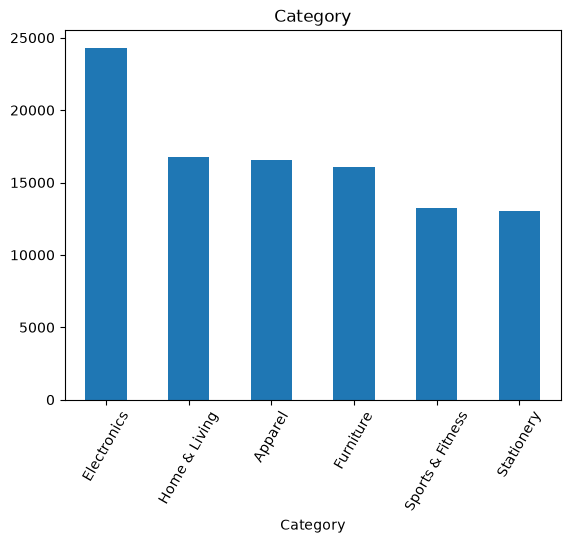

In [141]:
plt.Figure(figsize=(10,8))
df['Category'].value_counts().plot(kind='bar')
plt.xticks(rotation = 60)
plt.title('Category')
plt.show()

In [142]:
df['Product'].value_counts()

Product
Laptop Stand         6974
Dumbbell Set         6936
Pen Pack             6872
Table Lamp           6465
Study Table          6415
Yoga Mat             6307
Running Shoes        6297
USB-C Cable          6215
Notebook Set         6176
Curtains             5851
Bluetooth Speaker    5649
T-Shirt              5556
Wireless Mouse       5476
Office Chair         5254
Backpack             4682
Bed Sheet Set        4479
Bookshelf            4396
Name: count, dtype: int64

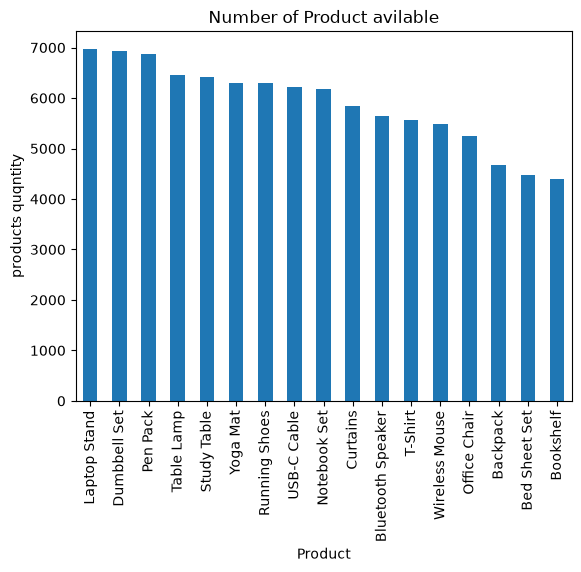

In [143]:
df['Product'].value_counts().plot(kind='bar')
plt.title('Number of Product avilable')
plt.xticks(rotation = 90)
plt.ylabel('products quqntity')
plt.show()


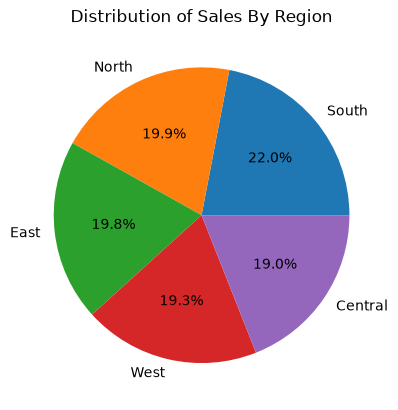

In [144]:
region = df['Region'].value_counts()
plt.pie(df['Region'].value_counts(),labels=region.index,autopct='%1.1f%%')
plt.title('Distribution of Sales By Region')
plt.show()


Text(0.5, 1.0, 'Distribution of Quantity sold')

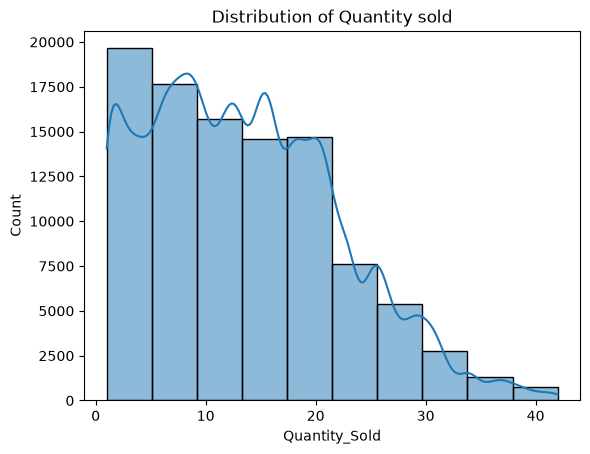

In [145]:
sns.histplot(df['Quantity_Sold'],bins= 10, kde= True)
plt.title('Distribution of Quantity sold')

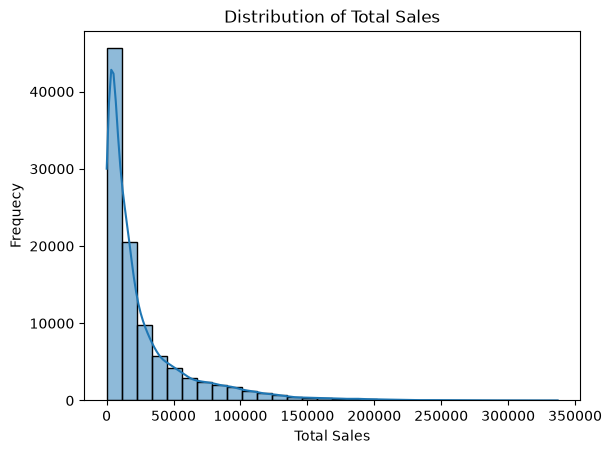

In [147]:
sns.histplot(df['Total_Sales'], bins= 30, kde= True)
plt.title('Distribution of Total Sales')
plt.xlabel('Total Sales')
plt.ylabel('Frequecy')
plt.show()

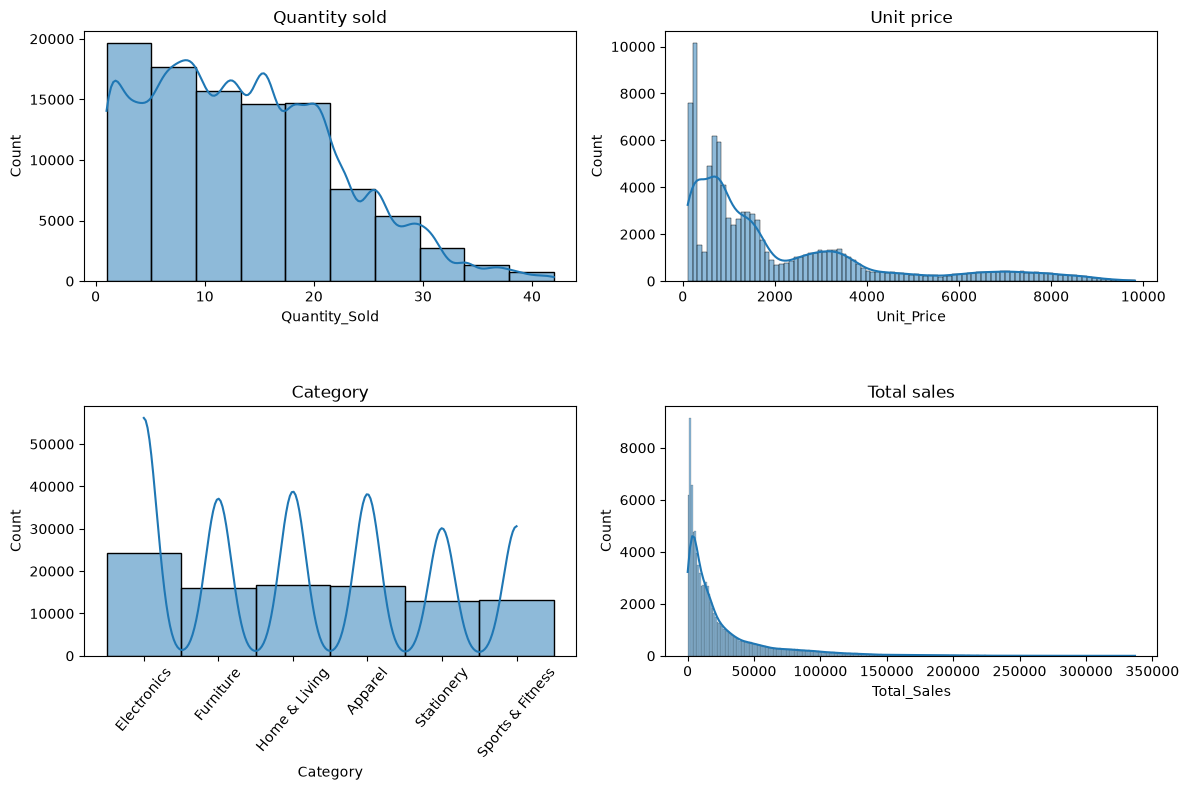

In [148]:
plt.figure(figsize=(12, 8))
plt.subplot(2,2,1)
sns.histplot(df['Quantity_Sold'],kde= True, bins=10)
plt.title('Quantity sold')

plt.subplot(2,2,2)
sns.histplot(df['Unit_Price'],kde= True)
plt.title('Unit price')

plt.subplot(2,2,3)
sns.histplot(df['Category'],kde= True)
plt.xticks(rotation = 50)
plt.title('Category')

plt.subplot(2,2,4)
sns.histplot(df['Total_Sales'],kde= True)
plt.title('Total sales')

plt.tight_layout()
plt.subplots_adjust(hspace=0.5)

# Bivariate Analysis

Text(0.5, 1.0, 'Quantity sold Vs Total Sales')

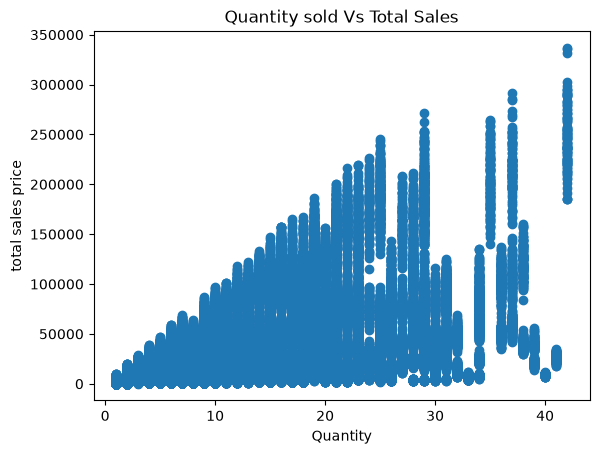

In [149]:
plt.scatter(df['Quantity_Sold'],df['Total_Sales'])
plt.xlabel('Quantity')
plt.ylabel('total sales price')
plt.title('Quantity sold Vs Total Sales')

Text(0.5, 1.0, 'Discount Vs Total Sales')

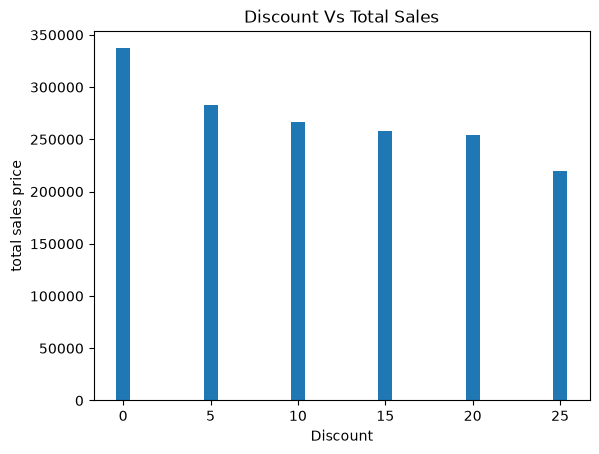

In [31]:
plt.bar(df['Discount'],df['Total_Sales'])
plt.xlabel('Discount')
plt.ylabel('total sales price')
plt.title('Discount Vs Total Sales')

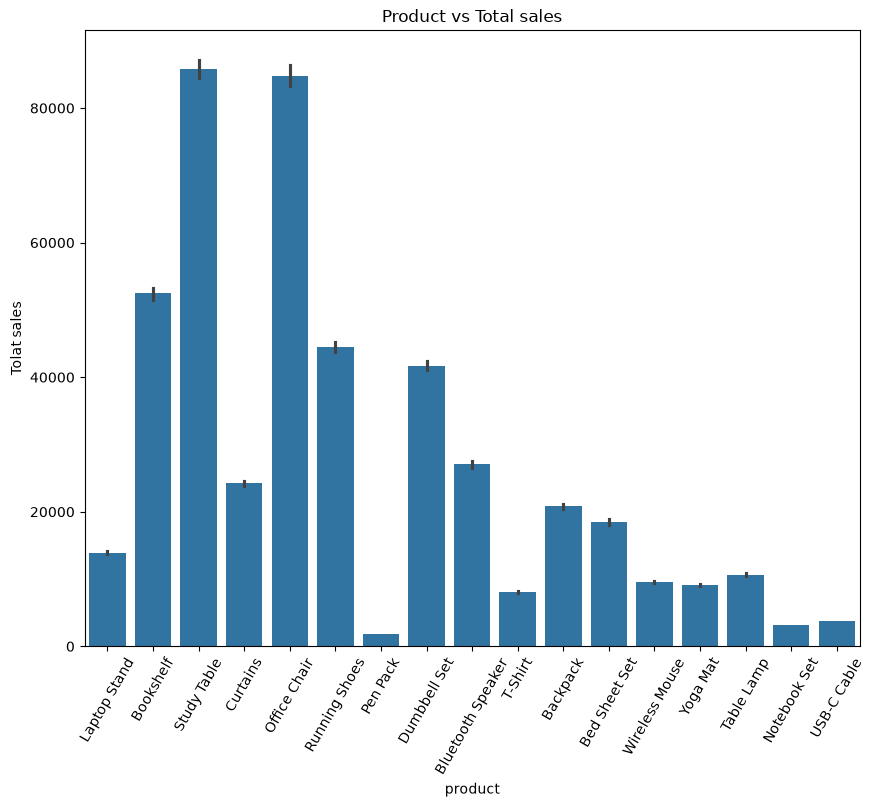

In [150]:
plt.figure(figsize=(10,8))
sns.barplot(data=df, x='Product', y='Total_Sales')
plt.xlabel("product")
plt.ylabel("Tolat sales")
plt.xticks(rotation = 60)
plt.title("Product vs Total sales")
plt.show()

<Axes: >

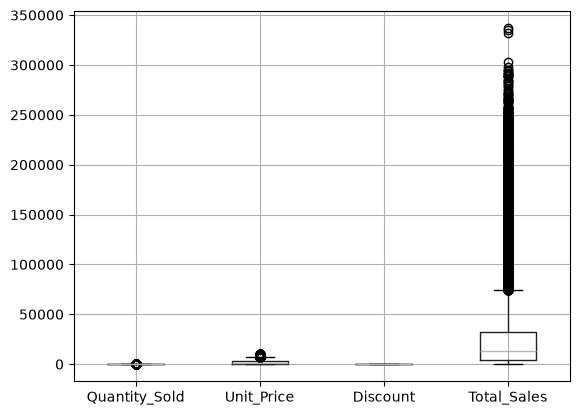

In [151]:
df[['Quantity_Sold','Unit_Price','Discount','Total_Sales']].boxplot()

## Removing Outliers Using IQR

7.0
20.0


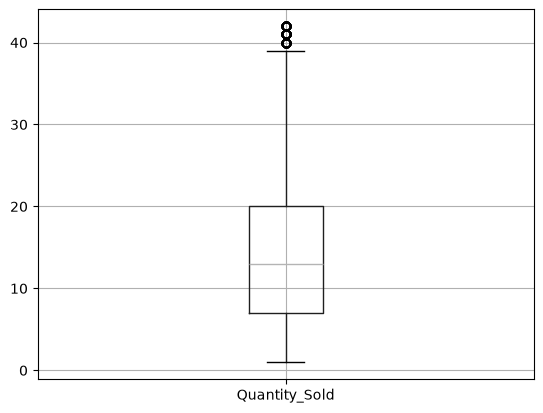

In [152]:
df[['Quantity_Sold']].boxplot()
Q1 = df['Quantity_Sold'].quantile(0.25)
Q3 = df['Quantity_Sold'].quantile(0.75)
print(Q1)
print(Q3)

In [153]:
IQR = Q3 - Q1
print(IQR)
UL = Q3 + 1.5*IQR
LL = Q1 - 1.5*IQR
print(UL)
print(LL)
df[(df['Quantity_Sold'] > UL) | (df['Quantity_Sold'] < LL)]

13.0
39.5
-12.5


,Date,Product,Category,Region,Quantity_Sold,Unit_Price,Discount,Total_Sales
345,2016-01-16,Yoga Mat,Sports & Fitness,South,41,534.59,15.0,18630.46
456,2016-01-22,Notebook Set,Stationery,North,40,191.91,0.0,7676.40
944,2016-02-15,Office Chair,Furniture,North,42,5183.23,15.0,185041.31
982,2016-02-17,Yoga Mat,Sports & Fitness,South,41,610.10,5.0,23763.40
995,2016-02-18,Notebook Set,Stationery,West,40,222.95,5.0,8472.10
...,...,...,...,...,...,...,...,...
98931,2025-12-04,Notebook Set,Stationery,Central,40,247.63,10.0,8914.68
99265,2025-12-13,Yoga Mat,Sports & Fitness,East,41,765.10,5.0,29800.64
99287,2025-12-14,Office Chair,Furniture,North,42,7026.55,20.0,236092.08
99522,2025-12-19,Office Chair,Furniture,Central,42,6221.95,10.0,235189.71


In [154]:
#CAPPING
import numpy as np
df['Quantity_Sold'] = np.where(df['Quantity_Sold'] > UL,
         UL,
         np.where(df['Quantity_Sold'] < LL,
                  LL,
                  df['Quantity_Sold']))

df

,Date,Product,Category,Region,Quantity_Sold,Unit_Price,Discount,Total_Sales
0,2016-01-01,Laptop Stand,Electronics,North,10.0,1025.96,5.0,9746.62
1,2016-01-01,Bookshelf,Furniture,South,9.0,3977.41,0.0,35796.69
2,2016-01-01,Study Table,Furniture,East,19.0,5782.85,5.0,104380.44
3,2016-01-01,Curtains,Home & Living,West,10.0,1525.69,15.0,12968.37
4,2016-01-01,Office Chair,Furniture,East,20.0,5483.98,10.0,98711.64
...,...,...,...,...,...,...,...,...
99995,2025-12-31,Office Chair,Furniture,South,6.0,6930.31,5.0,39502.77
99996,2025-12-31,Curtains,Home & Living,East,9.0,1950.07,0.0,17550.63
99997,2025-12-31,Bookshelf,Furniture,East,8.0,5218.81,25.0,31312.86
99998,2025-12-31,Study Table,Furniture,Central,6.0,8841.11,5.0,50394.33


<Axes: >

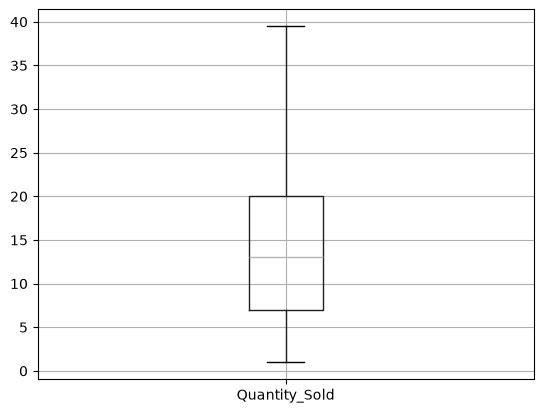

In [155]:
df[['Quantity_Sold']].boxplot()

<Axes: >

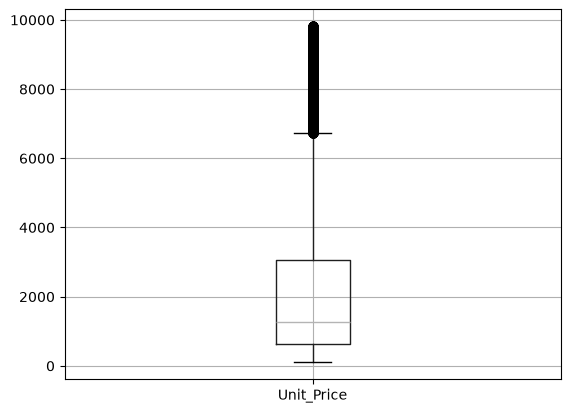

In [156]:
df[['Unit_Price']].boxplot()

### As you can see it is strongly right skewed so  I have to do log Transform

<Axes: xlabel='Unit_Price', ylabel='Count'>

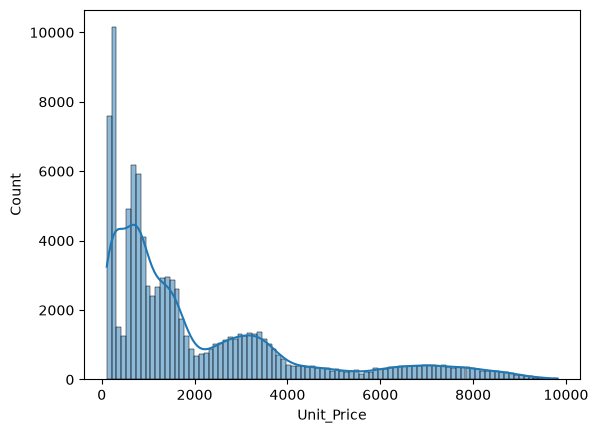

In [157]:
sns.histplot(df['Unit_Price'], kde=True)

In [158]:
df['Unit_Price_log'] = np.log1p(df['Unit_Price'])

<Axes: >

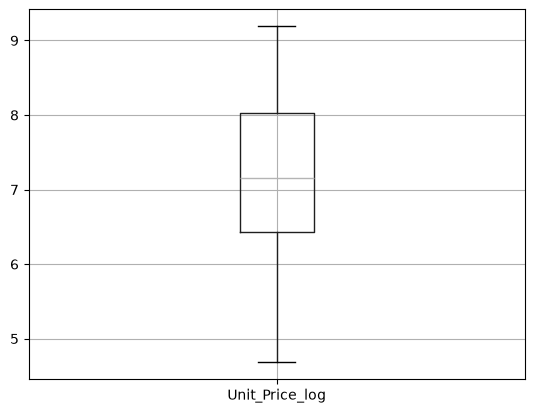

In [159]:
df[['Unit_Price_log']].boxplot()

In [160]:
df

,Date,Product,Category,Region,Quantity_Sold,Unit_Price,Discount,Total_Sales,Unit_Price_log
0,2016-01-01,Laptop Stand,Electronics,North,10.0,1025.96,5.0,9746.62,6.934358
1,2016-01-01,Bookshelf,Furniture,South,9.0,3977.41,0.0,35796.69,8.288638
2,2016-01-01,Study Table,Furniture,East,19.0,5782.85,5.0,104380.44,8.662825
3,2016-01-01,Curtains,Home & Living,West,10.0,1525.69,15.0,12968.37,7.330857
4,2016-01-01,Office Chair,Furniture,East,20.0,5483.98,10.0,98711.64,8.609769
...,...,...,...,...,...,...,...,...,...
99995,2025-12-31,Office Chair,Furniture,South,6.0,6930.31,5.0,39502.77,8.843804
99996,2025-12-31,Curtains,Home & Living,East,9.0,1950.07,0.0,17550.63,7.576133
99997,2025-12-31,Bookshelf,Furniture,East,8.0,5218.81,25.0,31312.86,8.560216
99998,2025-12-31,Study Table,Furniture,Central,6.0,8841.11,5.0,50394.33,9.087281


<Axes: >

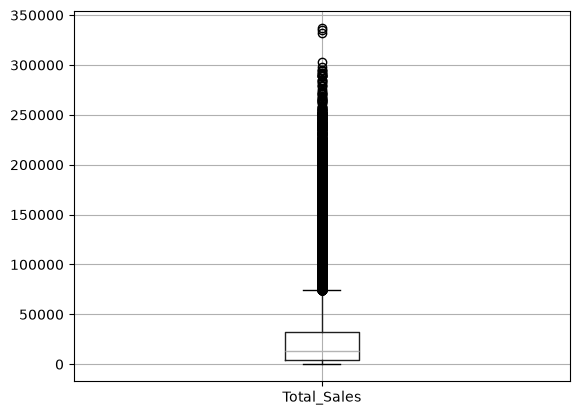

In [161]:
df[['Total_Sales']].boxplot()

In [162]:
print(df['Total_Sales'].describe())
print("skewness: ",df['Total_Sales'].skew())

count    100000.000000
mean      26472.359727
std       35318.186216
min          86.250000
25%        4507.267500
50%       13224.640000
75%       32543.097500
max      336973.560000
Name: Total_Sales, dtype: float64
skewness:  2.5367303728967556


<Axes: xlabel='Total_Sales', ylabel='Count'>

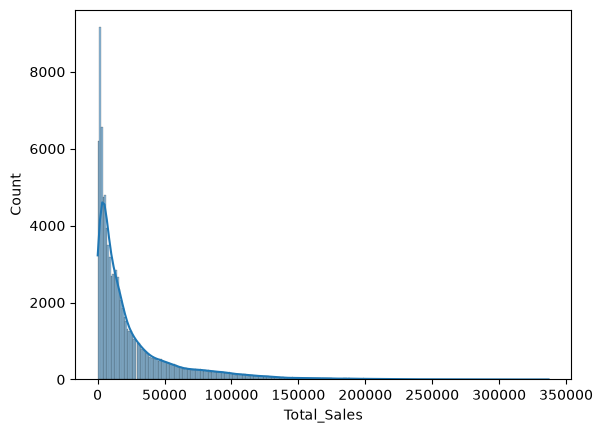

In [163]:
sns.histplot(df['Total_Sales'], kde=True)

In [164]:
df['Total_Sales_log'] = np.log1p(df['Total_Sales'])

In [165]:
df

,Date,Product,Category,Region,Quantity_Sold,Unit_Price,Discount,Total_Sales,Unit_Price_log,Total_Sales_log
0,2016-01-01,Laptop Stand,Electronics,North,10.0,1025.96,5.0,9746.62,6.934358,9.184778
1,2016-01-01,Bookshelf,Furniture,South,9.0,3977.41,0.0,35796.69,8.288638,10.485639
2,2016-01-01,Study Table,Furniture,East,19.0,5782.85,5.0,104380.44,8.662825,11.555807
3,2016-01-01,Curtains,Home & Living,West,10.0,1525.69,15.0,12968.37,7.330857,9.470346
4,2016-01-01,Office Chair,Furniture,East,20.0,5483.98,10.0,98711.64,8.609769,11.499968
...,...,...,...,...,...,...,...,...,...,...
99995,2025-12-31,Office Chair,Furniture,South,6.0,6930.31,5.0,39502.77,8.843804,10.584151
99996,2025-12-31,Curtains,Home & Living,East,9.0,1950.07,0.0,17550.63,7.576133,9.772902
99997,2025-12-31,Bookshelf,Furniture,East,8.0,5218.81,25.0,31312.86,8.560216,10.351816
99998,2025-12-31,Study Table,Furniture,Central,6.0,8841.11,5.0,50394.33,9.087281,10.827654


<Axes: >

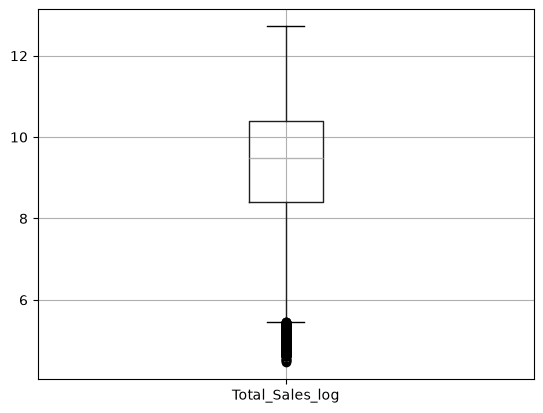

In [166]:
df[['Total_Sales_log']].boxplot()

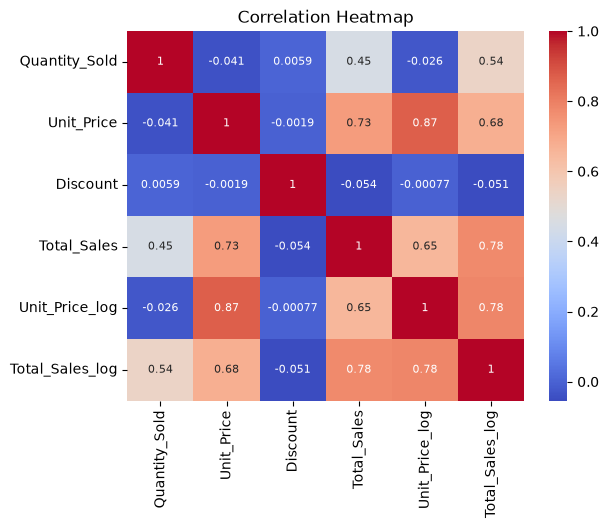

In [167]:
plt.Figure(figsize=(20,16))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    annot_kws={'size': 8}
)

plt.title('Correlation Heatmap')
plt.show()

## Feature Engineering

In [168]:
df['Date'] = pd.to_datetime(df['Date'])

In [169]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 10 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   Date             100000 non-null  datetime64[us]
 1   Product          100000 non-null  str           
 2   Category         100000 non-null  str           
 3   Region           100000 non-null  str           
 4   Quantity_Sold    100000 non-null  float64       
 5   Unit_Price       100000 non-null  float64       
 6   Discount         100000 non-null  float64       
 7   Total_Sales      100000 non-null  float64       
 8   Unit_Price_log   100000 non-null  float64       
 9   Total_Sales_log  100000 non-null  float64       
dtypes: datetime64[us](1), float64(6), str(3)
memory usage: 10.2 MB


In [170]:
df['year'] = df['Date'].dt.year

In [171]:
df['Month'] = df['Date'].dt.month

In [172]:
df

,Date,Product,Category,Region,Quantity_Sold,Unit_Price,Discount,Total_Sales,Unit_Price_log,Total_Sales_log,year,Month
0,2016-01-01,Laptop Stand,Electronics,North,10.0,1025.96,5.0,9746.62,6.934358,9.184778,2016,1
1,2016-01-01,Bookshelf,Furniture,South,9.0,3977.41,0.0,35796.69,8.288638,10.485639,2016,1
2,2016-01-01,Study Table,Furniture,East,19.0,5782.85,5.0,104380.44,8.662825,11.555807,2016,1
3,2016-01-01,Curtains,Home & Living,West,10.0,1525.69,15.0,12968.37,7.330857,9.470346,2016,1
4,2016-01-01,Office Chair,Furniture,East,20.0,5483.98,10.0,98711.64,8.609769,11.499968,2016,1
...,...,...,...,...,...,...,...,...,...,...,...,...
99995,2025-12-31,Office Chair,Furniture,South,6.0,6930.31,5.0,39502.77,8.843804,10.584151,2025,12
99996,2025-12-31,Curtains,Home & Living,East,9.0,1950.07,0.0,17550.63,7.576133,9.772902,2025,12
99997,2025-12-31,Bookshelf,Furniture,East,8.0,5218.81,25.0,31312.86,8.560216,10.351816,2025,12
99998,2025-12-31,Study Table,Furniture,Central,6.0,8841.11,5.0,50394.33,9.087281,10.827654,2025,12


In [199]:
x = df[[
    'year',
    'Product',
    'Category',
    'Region',
    'Quantity_Sold',
    'Unit_Price_log',
    'Discount'
]]

In [200]:
x

,year,Product,Category,Region,Quantity_Sold,Unit_Price_log,Discount
0,2016,Laptop Stand,Electronics,North,10.0,6.934358,5.0
1,2016,Bookshelf,Furniture,South,9.0,8.288638,0.0
2,2016,Study Table,Furniture,East,19.0,8.662825,5.0
3,2016,Curtains,Home & Living,West,10.0,7.330857,15.0
4,2016,Office Chair,Furniture,East,20.0,8.609769,10.0
...,...,...,...,...,...,...,...
99995,2025,Office Chair,Furniture,South,6.0,8.843804,5.0
99996,2025,Curtains,Home & Living,East,9.0,7.576133,0.0
99997,2025,Bookshelf,Furniture,East,8.0,8.560216,25.0
99998,2025,Study Table,Furniture,Central,6.0,9.087281,5.0


In [223]:
y= df['Total_Sales_log']

In [224]:
y

0         9.184778
1        10.485639
2        11.555807
3         9.470346
4        11.499968
           ...    
99995    10.584151
99996     9.772902
99997    10.351816
99998    10.827654
99999    10.055094
Name: Total_Sales_log, Length: 100000, dtype: float64

In [225]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2, random_state=100)

In [226]:
x_train

,year,Product,Category,Region,Quantity_Sold,Unit_Price_log,Discount
52529,2022,Dumbbell Set,Sports & Fitness,East,16.0,8.106521,0.0
73974,2023,Bookshelf,Furniture,Central,3.0,8.337325,5.0
20985,2018,Yoga Mat,Sports & Fitness,West,13.0,6.374070,5.0
25914,2019,Yoga Mat,Sports & Fitness,East,26.0,6.377696,0.0
77095,2024,USB-C Cable,Electronics,West,11.0,5.713039,0.0
...,...,...,...,...,...,...,...
65615,2023,Running Shoes,Apparel,West,11.0,8.134297,10.0
77655,2024,Backpack,Apparel,East,12.0,7.470116,5.0
79683,2024,Notebook Set,Stationery,East,4.0,5.591696,15.0
56088,2022,Office Chair,Furniture,South,4.0,8.881471,10.0


In [227]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [228]:
cate_col = ['Product','Category','Region']

In [229]:
num_col = ['year','Quantity_Sold','Unit_Price_log','Discount']

In [230]:
tf= ColumnTransformer([
    ('tfoe',OneHotEncoder(sparse_output=False,handle_unknown='ignore'),cate_col),
    ('tfse',StandardScaler(),num_col)
],remainder='passthrough')

In [231]:
tf

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('tfoe', ...), ('tfse', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``featu

## Not Important
### To visualize the transformed x_train And Y_train data in perfect DataFrame not in 0 or 1

In [232]:
transformed_x_train = tf.fit_transform(x_train)
transformed_x_tr= pd.DataFrame(
    transformed_x_train,
    columns=tf.get_feature_names_out()
)

In [233]:
transformed_x_test = tf.transform(x_test)
transformed_x_ts= pd.DataFrame(
    transformed_x_test,
    columns=tf.get_feature_names_out()
)

In [234]:
transformed_x_tr

,tfoe__Product_Backpack,tfoe__Product_Bed Sheet Set,tfoe__Product_Bluetooth Speaker,tfoe__Product_Bookshelf,tfoe__Product_Curtains,tfoe__Product_Dumbbell Set,tfoe__Product_Laptop Stand,tfoe__Product_Notebook Set,tfoe__Product_Office Chair,tfoe__Product_Pen Pack,...,tfoe__Category_Stationery,tfoe__Region_Central,tfoe__Region_East,tfoe__Region_North,tfoe__Region_South,tfoe__Region_West,tfse__year,tfse__Quantity_Sold,tfse__Unit_Price_log,tfse__Discount
0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.344900,0.275121,0.883040,-0.988751
1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.696785,-1.244133,1.087289,-0.256485
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,-1.062641,-0.075476,-0.650087,-0.256485
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,-0.710755,1.443778,-0.646879,-0.988751
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.048671,-0.309208,-1.235064,-0.988751
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79995,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.696785,-0.309208,0.907621,0.475781
79996,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.048671,-0.192342,0.319855,-0.256485
79997,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,1.048671,-1.127268,-1.342447,1.208047
79998,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.344900,-1.127268,1.568830,0.475781


In [235]:
transformed_x_ts

,tfoe__Product_Backpack,tfoe__Product_Bed Sheet Set,tfoe__Product_Bluetooth Speaker,tfoe__Product_Bookshelf,tfoe__Product_Curtains,tfoe__Product_Dumbbell Set,tfoe__Product_Laptop Stand,tfoe__Product_Notebook Set,tfoe__Product_Office Chair,tfoe__Product_Pen Pack,...,tfoe__Category_Stationery,tfoe__Region_Central,tfoe__Region_East,tfoe__Region_North,tfoe__Region_South,tfoe__Region_West,tfse__year,tfse__Quantity_Sold,tfse__Unit_Price_log,tfse__Discount
0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,-1.062641,0.158255,0.694232,-0.256485
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,-0.710755,2.378704,-1.613741,-0.988751
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,-1.414526,0.275121,1.528630,-0.988751
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.696785,-1.360999,0.223643,0.475781
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,-0.358870,1.093181,0.098924,0.475781
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,-1.062641,0.275121,-0.445259,0.475781
19996,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.400556,1.093181,-0.701053,1.940313
19997,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.344900,-0.426073,1.650907,-0.988751
19998,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.400556,-0.192342,-0.435295,-0.256485


In [236]:
from sklearn.linear_model import LinearRegression

In [237]:
pipe = Pipeline([
    ('preprocessing',tf),
    ('model', LinearRegression())
])

In [238]:
pipe.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['year','Product','Category',...,'Quantity_Sold','Unit_Price_log', 'Discount']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('tfoe', ...), ('tfse', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of

In [239]:
y_pred = pipe.predict(x_test)

In [240]:
print(y_pred)

[10.33411484  9.49588265 11.40205508 ... 10.99035273  8.72243314
  9.37969196]


In [241]:
print(y_test)

22422    10.549575
25747     8.806562
13795    11.608498
68724     7.948897
38923    10.249899
           ...    
15656     9.271497
88084     9.227120
52924    11.276690
87959     9.049181
11767     9.453727
Name: Total_Sales_log, Length: 20000, dtype: float64


In [242]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score,root_mean_squared_error
import numpy as np

In [243]:
print('MAE',mean_absolute_error(y_test,y_pred))
print("MSE",mean_squared_error(y_test,y_pred))
print("RMSE",np.sqrt(mean_squared_error(y_test,y_pred)))
print("R2_score",r2_score(y_test,y_pred))

MAE 0.2841199303613686
MSE 0.14546446920377434
RMSE 0.38139804562133556
R2_score 0.9272035931224946


In [246]:
import pickle

pickle.dump(pipe,open('Sales_Model2.pkl','wb'))